# 从今往后你就能操作数据管线了！—— Python、NumPy、pandas、DuckDB 与 matplotlib 入门

课堂中的数据旅程是：

`下传字节 → 可信物理量 → 表格与查询 → 光变曲线 / 能谱`

这份 Notebook 从整理好的事件表继续：先补齐一点 Python 基础，再认识处理表格、查询和绘图所需的工具，最后处理一次真实的伽马射线暴事件数据。

学完以后，你可以：

- 看懂变量、列表、缩进、函数调用和 `对象.方法()`；
- 用 pandas 读取、检查、清洗和筛选表格；
- 用 DuckDB 删除重复记录并按时间排序；
- 用 NumPy 分箱；
- 用 matplotlib 分别画出光变曲线和计数能谱。

不需要先背语法。按顺序运行，观察每格的输入和输出即可。


## 0. 开始运行

Jupyter Notebook 类似“代码笔记本”：代码、说明和图片可以放在一起，并且能够分小块逐段运行。

在 JupyterLab、Notebook 或 VS Code 中打开本文件。点击代码单元格后按 `Shift + Enter` 运行；VS Code 也可以点击单元格左边的小三角。

- 第一次运行时，先执行下面的安装单元格。
- 如果安装后仍提示 `ModuleNotFoundError`，请重启 kernel，再继续运行。
- `#` 后面是注释，只是写给人看的说明，不会被 Python 执行。
- **图里的文字一律用英文。** matplotlib 自带的默认字体不含汉字，标题、坐标轴或图例写中文会显示成一串方框，并在输出里刷出大量 `Glyph missing from font` 警告。本 Notebook 的所有图都用英文标注。
- 如果你确实想写中文标题，需要自己指定一个本机装了的中文字体，例如：

```python
import matplotlib

# 字体名要和你机器上真实装了的对得上：Windows 常见 Microsoft YaHei / SimHei，macOS 常见 PingFang SC。
matplotlib.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "PingFang SC", "Noto Sans CJK SC"]
matplotlib.rcParams["axes.unicode_minus"] = False  # 否则坐标轴上的负号也会变成方框
```


In [ ]:
%pip install -q numpy pandas duckdb matplotlib


## 1. Python 最少必备知识

Python 是一种语法相对简单、生态丰富的高级编程语言，适合快速处理数据、写脚本和做科学计算。这里不追求完整学习 Python，只补齐读懂后续代码所需的基础。

### 1.1 变量：给一个值起名字

`=` 表示“把右边的值交给左边这个名字”。变量可以保存文字、整数、小数和真假值。

变量名区分大小写。`price` 和 `Price` 是两个不同的名字。


In [2]:
product = "柠檬茶"   # str：字符串，也就是文字
price = 12.0          # float：小数
quantity = 3          # int：整数
is_member = True      # bool：只有 True 和 False 两种值

total = price * quantity

print(product)
print("总价：", total, "元")
print("变量 total 的类型：", type(total))


柠檬茶
总价： 36.0 元
变量 total 的类型： <class 'float'>


### 1.2 list：把一串值按顺序放在一起

列表写在方括号 `[]` 中。Python 从 **0** 开始编号，所以 `prices[0]` 是第一个元素。

切片 `prices[start:stop]` 包含 `start`，不包含 `stop`。


In [3]:
prices = [12, 18, 16, 12]

print("完整列表：", prices)
print("第一个价格：", prices[0])
print("第 2、3 个价格：", prices[1:3])
print("列表长度：", len(prices))


完整列表： [12, 18, 16, 12]
第一个价格： 12
第 2、3 个价格： [18, 16]
列表长度： 4


### 1.3 条件、循环与缩进

`if` 表示“如果”，`for` 表示“依次处理”。冒号 `:` 后面的代码必须缩进；同一层通常缩进 4 个空格。

缩进不是为了好看，而是在告诉 Python 哪几行属于 `if` 或 `for`。缩进层级不一致会报错，或改变程序含义。


In [4]:
for current_price in prices:          # 依次取出列表中的每个价格
    if current_price >= 15:            # 如果当前价格至少为 15
        print(current_price, "元：较贵") # 这一行同时属于 for 和 if
    else:
        print(current_price, "元：较便宜")

print("循环结束")  # 没有缩进，所以不在循环里，只运行一次


12 元：较便宜
18 元：较贵
16 元：较贵
12 元：较便宜
循环结束


### 1.4 函数调用与返回值

`print(...)`、`len(...)` 都是在调用函数。圆括号 `()` 里放输入，函数完成工作后可能返回一个结果。

把函数的返回值交给变量，就可以继续使用这个结果。


In [5]:
number_of_prices = len(prices)  # len 返回列表长度
rounded_price = round(12.345, 2) # round 返回保留两位小数的结果

print("价格数量：", number_of_prices)
print("保留两位小数：", rounded_price)


价格数量： 4
保留两位小数： 12.35


## 2. 为什么代码里经常出现“名字.方法()”？

库可以理解成一组整理、封装好的代码。别人把常用功能实现并测试好，我们通过稳定接口复用，不必每次从头编写。

- `%pip install 库名`：把库安装到当前 Python 环境，通常只需安装一次；
- `import 库名`：让当前程序能够访问它；每次重启 kernel 后都要重新导入；
- `as`：给导入的库起一个短名字。

点号 `.` 表示“到这个东西里面寻找一个名字”，但常见的两种写法略有不同：

- `np.arange(...)`：在 NumPy 这个**模块**中找到 `arange` 函数；
- `numbers.mean()`：让 `numbers` 这个**数组对象**调用自己的 `mean` 方法。

平时可以都粗略理解为“使用它提供的功能”。圆括号表示调用；没有圆括号的 `.shape` 则是在读取一个属性。


In [6]:
from pathlib import Path              # Path 用来表示文件路径

import duckdb                         # SQL 数据分析工具
import matplotlib.pyplot as plt       # 画图工具，简称 plt
import numpy as np                    # 数值计算工具，简称 np
import pandas as pd                   # 表格处理工具，简称 pd

numbers = np.array([2, 4, 6, 8])      # np.array：模块中的函数

print("数组：", numbers)
print("平均值：", numbers.mean())     # numbers.mean：数组对象的方法
print("形状：", numbers.shape)        # shape 是属性，所以后面没有 ()


Matplotlib created a temporary config/cache directory at /var/folders/z0/z_svy8k93fv7g5c3vwq9kkc80000gn/T/matplotlib-7ph8ek5l because the default path (/Users/zhufeiyang/.matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


/Users/zhufeiyang/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


数组： [2 4 6 8]
平均值： 5.0
形状： (4,)


还会经常看到连续的点号，例如：

```python
table["name"].astype("string").str.strip()
```

它的阅读顺序是从左到右：先从表中取出 `name` 列，再转成字符串，最后去掉每个字符串首尾的空格。前一步返回的结果，成为后一步操作的对象。


## 3. NumPy：数组、区间边界和分箱

NumPy 的数组像规则排列的一格格数据，每格通常保存同一类数。`shape` 描述数组沿各个方向有多少格；NumPy 能让一批数字一起参加运算。

这份作业主要需要三个函数：

- `np.array(...)`：创建数组；
- `np.arange(start, stop, step)`：生成等间隔数字，包含 `start`，不包含 `stop`；
- `np.histogram(values, bins=edges)`：统计每个区间中有多少个值。


In [7]:
# 6 位顾客进入商店的时间，单位为分钟。
arrival_minutes = np.array([0.2, 0.7, 1.3, 1.9, 3.4, 3.8])

# 从 0 到 5，每隔 1 取一个数。5 是 stop，因此不会被包含。
minute_edges = np.arange(0, 5, 1)

print("顾客到店时间：", arrival_minutes)
print("区间边界：", minute_edges)


顾客到店时间： [0.2 0.7 1.3 1.9 3.4 3.8]
区间边界： [0 1 2 3 4]


边界 `[0, 1, 2, 3, 4]` 划出了 4 个区间：`[0, 1)`、`[1, 2)`、`[2, 3)`、`[3, 4]`。

`np.histogram` 返回两个结果，所以左边写两个变量。这里第二个返回值仍是边界；如果已经有 `minute_edges`，可以用 `_` 表示“这个结果暂时不用”。


In [8]:
arrivals_per_minute, returned_edges = np.histogram(
    arrival_minutes,
    bins=minute_edges,
)

print("每个区间的人数：", arrivals_per_minute)
print("返回的边界：", returned_edges)

# 同一种常用写法：只保留计数，忽略第二个返回值。
arrivals_per_minute, _ = np.histogram(arrival_minutes, bins=minute_edges)


每个区间的人数： [2 2 0 2]
返回的边界： [0 1 2 3 4]


## 4. pandas：读取、检查和清洗表格

`DataFrame` 可以理解为一张有列名的二维表。每一行是一条记录，每一列记录一个属性。

下面的小表故意包含乱序、重复记录和一个缺失值，用来练习后面作业会遇到的动作。


In [9]:
orders = pd.DataFrame({
    "order_id": ["A003", "A001", "A004", "A002", "A003"],
    "hour": [14, 9, 16, 11, 14],
    "product": [" 柠檬茶 ", "拿铁", "可可", "柠檬茶", " 柠檬茶 "],
    "quantity": [3, 1, None, 2, 3],
})

display(orders)

print("表格形状（行数, 列数）：", orders.shape)
print("每列的数据类型：")
display(orders.dtypes)
print("每列的缺失值数量：")
display(orders.isna().sum())
print("product 中出现过的写法：", orders["product"].unique())


,order_id,hour,product,quantity
0,A003,14,柠檬茶,3.0
1,A001,9,拿铁,1.0
2,A004,16,可可,NaN
3,A002,11,柠檬茶,2.0
4,A003,14,柠檬茶,3.0


表格形状（行数, 列数）： (5, 4)
每列的数据类型：


order_id     object
hour          int64
product      object
quantity    float64
dtype: object

每列的缺失值数量：


order_id    0
hour        0
product     0
quantity    1
dtype: int64

product 中出现过的写法： [' 柠檬茶 ' '拿铁' '可可' '柠檬茶']


### 4.1 清洗一列

这些操作会在作业中再次出现：

- `astype("string")`：把一列统一转成字符串；
- `.str.strip()`：去掉字符串首尾空格；
- `pd.to_numeric(..., errors="coerce")`：转成数字，无法转换的内容变成缺失值；
- `dropna(subset=[...])`：删除指定列中有缺失值的行；
- `unique()`：查看一列中出现过哪些不同写法；
- `.copy()`：得到一份独立副本，后续修改不会意外影响原表。


In [10]:
orders_work = orders.copy()

orders_work["product"] = (
    orders_work["product"]
    .astype("string")
    .str.strip()
)
orders_work["quantity"] = pd.to_numeric(
    orders_work["quantity"],
    errors="coerce",
)

orders_clean = orders_work.dropna(subset=["quantity"]).copy()
display(orders_clean)


,order_id,hour,product,quantity
0,A003,14,柠檬茶,3.0
1,A001,9,拿铁,1.0
3,A002,11,柠檬茶,2.0
4,A003,14,柠檬茶,3.0


### 4.2 按条件筛选行

`table.loc[条件]` 只保留条件成立的行。多个条件同时成立时，用 `&` 连接，并给每个条件加括号。


In [11]:
# 只保留 10 点（含）到 15 点（不含）的订单。
selected_orders = orders_clean.loc[
    (orders_clean["hour"] >= 10) & (orders_clean["hour"] < 15)
].copy()

display(selected_orders)


,order_id,hour,product,quantity
0,A003,14,柠檬茶,3.0
3,A002,11,柠檬茶,2.0
4,A003,14,柠檬茶,3.0


## 5. DuckDB：去重和排序

卫星下传数据可能因为包重传而重复，也可能因为到达顺序与发生顺序不同而乱序。这里用数据库把记录恢复成“没有重复、按时间排列”的结果。

课堂前面提到的 IoTDB 常作为长期运行的服务；DuckDB 更像嵌入本地程序的分析引擎。它可以直接在 Python 中查询 CSV、Parquet 或 pandas 表格，不需要先启动数据库服务器。

这份作业只使用：

- `SELECT DISTINCT *`：删除完全相同的重复行；
- `ORDER BY 列名`：按指定列排序。

`con.register("orders", orders_clean)` 把一个 DataFrame 临时登记成 SQL 中可查询的表。


In [12]:
con = duckdb.connect()                    # 建立临时数据库连接
con.register("orders", orders_clean)      # 把 DataFrame 注册为 orders 表

orders_tidy = con.sql('''
    SELECT DISTINCT *
    FROM orders
    ORDER BY hour
''').df()                                  # .df() 把查询结果取回 DataFrame

display(orders_tidy)


,order_id,hour,product,quantity
0,A001,9,拿铁,1.0
1,A002,11,柠檬茶,2.0
2,A003,14,柠檬茶,3.0


## 6. matplotlib：把分箱结果画成阶梯图

这份作业只需要一张图一个坐标系：`fig, ax = plt.subplots()`。

- `fig` 是整张画布；
- `ax` 是画布中的坐标系；
- `ax.step(...)` 画阶梯线；
- `label="..."` 给曲线命名，`ax.legend()` 显示图例；
- 标题和坐标轴名称负责告诉读者“画的是什么、单位是什么”。


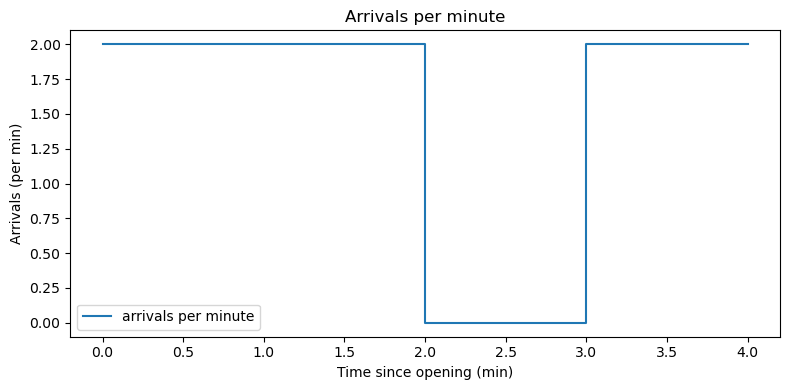

In [13]:
# 第 1 步：创建一张 8×4 英寸的图。
fig, ax = plt.subplots(figsize=(8, 4))

# 第 2 步：阶梯图的 x 要覆盖所有边界。
# counts 比 edges 少一个元素，因此把最后一个计数再补到 y 的末尾。
step_y = np.append(arrivals_per_minute, arrivals_per_minute[-1])

# where="post" 表示一个 y 值从当前左边界保持到下一个边界。
ax.step(
    minute_edges,
    step_y,
    where="post",
    label="arrivals per minute",
)

# 第 3 步：补齐读图需要的信息。
# 图中的文字用英文：matplotlib 默认字体不含汉字，写中文会变成方框（见「0. 开始运行」）。
ax.set_title("Arrivals per minute")
ax.set_xlabel("Time since opening (min)")
ax.set_ylabel("Arrivals (per min)")
ax.legend()

# 第 4 步：自动整理边距并显示图片。
fig.tight_layout()
plt.show()


到这里，各工具在作业中的分工如下：

| 工具 | 作业中负责什么 |
|---|---|
| pandas | 读取 CSV、检查缺失值、整理字段、筛选事件 |
| DuckDB | 删除重复行、按时间排序 |
| NumPy | 生成分箱边界、统计每个箱里的事件数 |
| matplotlib | 分别画光变曲线和计数能谱 |


# 7. 作业：从光子事件到光变曲线和计数能谱

**你需要完成以下TODO，提交最后的NoteBook和光变曲线图、能谱图**

数据文件：`GRID11B_GRB260714B_events_homework.csv`

请把 CSV 和 Notebook 放在同一个文件夹中，这样 `Path("GRID11B_GRB260714B_events_homework.csv")` 才能直接找到数据。

它来自天格 GRID11B 对 GRB 260714B 的事件记录，并经过教学化整理。数据**尚未分箱**：一行代表探测器记录到的一个事件。

| 列名 | 含义 |
|---|---|
| `event_id` | 事件编号；重复编号可能意味着重复行 |
| `detector` | 探测器编号，本题只分析 `E_0` |
| `time_s` | 相对触发时刻 T0 的时间，单位为秒 |
| `energy_keV` | 事件能量，单位为 keV；`E_3` 整列为空，见下面一段 |
| `adc_value` | 仪器原始 ADC 值；本题不使用 |

检查缺失值时会看到 `energy_keV` 空了五千多行，数量吓人，但几乎全部来自 `E_3`：这块探测器在这批数据里没有做能量标定，所以它的能量整列为空，本题也不用它。真正要分析的 `E_0` 只有个位数的空能量。

CSV 中包含乱序、重复行、空值、不合理能量值和书写不整齐的探测器名称，需要先清洗。乱序和重复对应前面讲过的下传数据问题；这次不再处理二进制数据和时间、能量重建，因为 CSV 已经给出了带单位的物理量。


In [14]:
data_path = Path("GRID11B_GRB260714B_events_homework.csv")
raw = pd.read_csv(data_path)

print("文件位置：", data_path.resolve())
print("形状（行数, 列数）：", raw.shape)
display(raw.head())

# 先观察，不要急着修改。
print("每列的数据类型：")
display(raw.dtypes)
print("每列的缺失值数量：")
display(raw.isna().sum())
print("detector 中出现过的写法：", raw["detector"].unique())

# 缺失的能量集中在谁身上？E_3 没有做能量标定，整列为空。
print("各探测器缺失的 energy_keV 数量：")
display(raw["energy_keV"].isna().groupby(raw["detector"].str.strip().str.upper()).sum())


文件位置： /Users/zhufeiyang/Documents/Codex/2026-09-28/zhe/outputs/GRID11B_GRB260714B_events_homework.csv
形状（行数, 列数）： (33373, 5)


,event_id,detector,time_s,energy_keV,adc_value
0,E_3-02930,E_3,19.219974,NaN,681
1,E_1-03893,E_1,6.427690,124.523683,754
2,E_2-03242,E_2,1.635852,133.109901,808
3,E_1-00118,E_1,-28.698454,40.614047,226
4,E_1-02404,E_1,-5.721559,1376.083734,8570


每列的数据类型：


event_id       object
detector       object
time_s        float64
energy_keV    float64
adc_value       int64
dtype: object

每列的缺失值数量：


event_id         0
detector         0
time_s           4
energy_keV    5279
adc_value        0
dtype: int64

detector 中出现过的写法： ['E_3' 'E_1' 'E_2' 'E_0' ' e_0 ']
各探测器缺失的 energy_keV 数量：


detector
E_0       8
E_1       0
E_2       0
E_3    5271
Name: energy_keV, dtype: int64

## 7.1 分箱前的数据是什么样？

每个光子事件都可以画成一个点：横坐标是到达时间，纵坐标是能量。

```text
Energy
  ↑
  │      ·
  │ ·         ·
  │    ·  ······· ·
  │       ·······
  │ ·       ·
  └────────────────→ Time
                GRB
```

背景事件通常较稀疏；GRB 到来时，一小段时间里会突然出现很多点。下面用模拟事件画一张示意图。这幅图不是作业数据，也不是作业答案；随机数部分只用于生成示意点，不需要模仿。


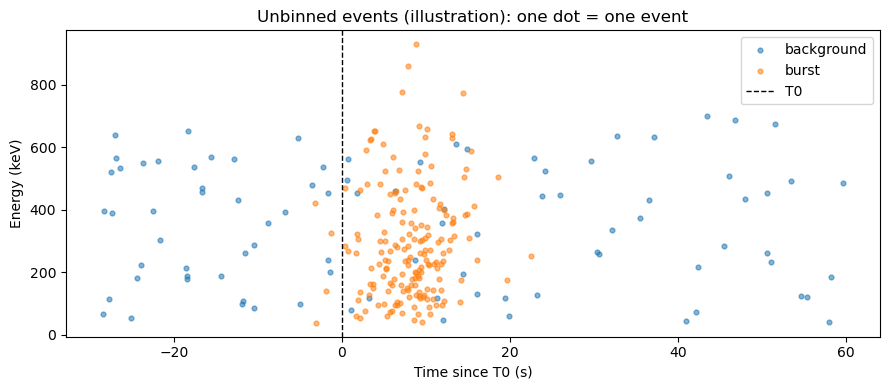

In [15]:
rng = np.random.default_rng(11)

background_time = rng.uniform(-30, 60, 90)
background_energy = rng.uniform(20, 700, 90)
burst_time = rng.normal(loc=8, scale=4, size=180)
burst_energy = rng.gamma(shape=2.2, scale=120, size=180) + 20

fig, ax = plt.subplots(figsize=(9, 4))
# 图中的文字用英文，原因见「0. 开始运行」。
ax.scatter(background_time, background_energy, s=12, alpha=0.55, label="background")
ax.scatter(burst_time, burst_energy, s=12, alpha=0.55, label="burst")
ax.axvline(0, color="black", linestyle="--", linewidth=1, label="T0")
ax.set_title("Unbinned events (illustration): one dot = one event")
ax.set_xlabel("Time since T0 (s)")
ax.set_ylabel("Energy (keV)")
ax.legend()
fig.tight_layout()
plt.show()


## 7.2 两种投影，两张图

- **光变曲线**：沿能量方向把点压到时间轴上，统计每个时间箱的事件数。它回答“什么时候变亮、持续多久”。
- **计数能谱**：沿时间方向把点压到能量轴上，统计每个能量箱的事件数。它回答“事件主要落在哪些能量范围”。

分箱就是区间统计：先定边界，再把每个值放进一个区间，最后统计每个区间中的记录数。

本题使用：

- 时间范围：`[-30, 60)` 秒；时间箱宽：1 秒；
- 能量范围：`(0, 1600]` keV；能量箱宽：50 keV；
- 只分析清洗后的 `E_0` 事件。


## 7.3 清洗并筛选 E_0

依次完成：

1. 复制原表；
2. 统一 `detector` 的大小写并去掉首尾空格；
3. 把 `time_s` 和 `energy_keV` 转成数字；
4. 删除时间或能量为空的行；
5. 选择 `E_0`，保留 `-30 <= time_s < 60`；
6. 只保留 `0 < energy_keV <= 1600`。

先不要去重和排序，下一步交给 DuckDB。


In [16]:
work = raw.copy()

# TODO 1：统一探测器编号的大小写，并去掉首尾空格。
work["detector"] = work["detector"].astype("string").str.strip().str.upper()

# TODO 2：将时间和能量转为数字；不能转换的值记为缺失。
work["time_s"] = pd.to_numeric(work["time_s"], errors="coerce")
work["energy_keV"] = pd.to_numeric(work["energy_keV"], errors="coerce")

# TODO 3：删除时间或能量缺失的记录。
work = work.dropna(subset=["time_s", "energy_keV"]).copy()

# TODO 4：按探测器、时间和能量范围筛选。
e0_candidates = work.loc[
    (work["detector"] == "E_0")
    & (work["time_s"] >= -30)
    & (work["time_s"] < 60)
    & (work["energy_keV"] > 0)
    & (work["energy_keV"] <= 1600)
].copy()

print("去重前候选事件数：", len(e0_candidates))
display(e0_candidates.head())

去重前候选事件数： 8722


,event_id,detector,time_s,energy_keV,adc_value
11,E_0-03485,E_0,6.517161,95.273281,570
15,E_0-06371,E_0,35.310019,58.882943,341
18,E_0-06986,E_0,42.696990,1387.211342,8639
20,E_0-05819,E_0,29.203018,52.528110,301
24,E_0-06378,E_0,35.786740,1381.405462,8603


## 7.4 用 DuckDB 去重并按时间排序

把 `e0_candidates` 注册为 SQL 表，然后使用 `SELECT DISTINCT *` 和 `ORDER BY time_s`。把查询结果取回 DataFrame，命名为 `e0`。


In [17]:
# TODO 5：注册候选事件表。
con = duckdb.connect()
con.register("e0_candidates", e0_candidates)

# TODO 6：删除完全相同的重复行，并按时间排序。
e0 = con.sql("""
    SELECT DISTINCT *
    FROM e0_candidates
    ORDER BY time_s
""").df()

print("清洗并去重后的 E_0 事件数：", len(e0))
assert len(e0) == 8704, "事件数不对，回到 7.3 逐条对照清洗步骤"
assert e0["time_s"].is_monotonic_increasing, "没有按 time_s 排好序"

清洗并去重后的 E_0 事件数： 8704


## 7.5 用 NumPy 分箱

`np.histogram(values, bins=edges)` 返回每个箱的事件数和箱边界。

1 秒时间箱中，“每箱事件数”和“每秒事件数”的数值相同；仍建议明确除以箱宽，这样改用 0.5 秒箱时也不会出错。


In [18]:
time_bin_width = 1
time_edges = np.arange(-30, 60 + time_bin_width, time_bin_width)

energy_bin_width = 50
energy_edges = np.arange(0, 1600 + energy_bin_width, energy_bin_width)

# TODO 7：统计各 1 秒时间箱的事件数。
time_counts, _ = np.histogram(e0["time_s"], bins=time_edges)

# TODO 8：计算每秒计数率。
time_rate = time_counts / time_bin_width

# TODO 9：统计各 50 keV 能量箱的事件数。
energy_counts, _ = np.histogram(e0["energy_keV"], bins=energy_edges)

print("时间：", len(time_counts), "个箱，", len(time_edges), "条边界")
print("能量：", len(energy_counts), "个箱，", len(energy_edges), "条边界")
print("时间分箱事件总数：", time_counts.sum())
print("能量分箱事件总数：", energy_counts.sum())
assert time_counts.sum() == energy_counts.sum() == len(e0)

时间： 90 个箱， 91 条边界
能量： 32 个箱， 33 条边界
时间分箱事件总数： 8704
能量分箱事件总数： 8704


## 7.6 画第一张图：光变曲线

使用 `ax.step(...)`。横轴是时间边界，纵轴是计数率；记得给 y 在末尾补一个值，使长度与边界一致。


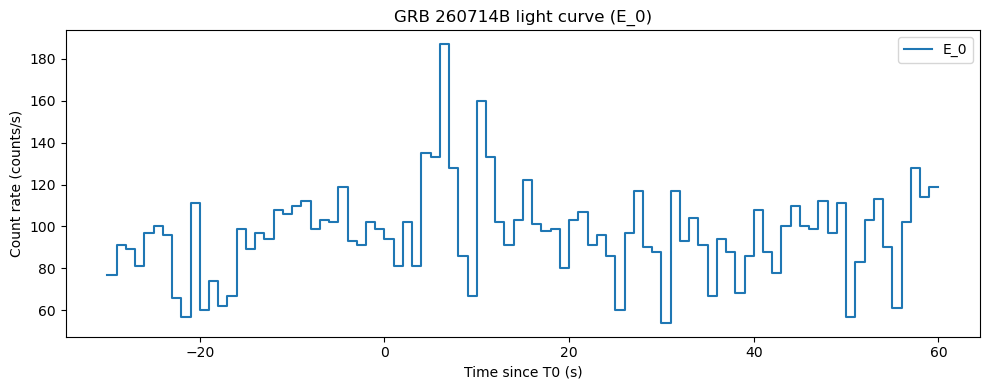

In [19]:
# TODO 10：创建光变曲线画布。
fig, ax = plt.subplots(figsize=(10, 4))

# TODO 11：补齐阶梯线末端，并画出每秒计数率。
lightcurve_y = np.append(time_rate, time_rate[-1])
ax.step(time_edges, lightcurve_y, where="post", label="E_0")

# TODO 12：添加标题、带单位的坐标轴名称和图例。
ax.set_title("GRB 260714B light curve (E_0)")
ax.set_xlabel("Time since T0 (s)")
ax.set_ylabel("Count rate (counts/s)")
ax.legend()

# TODO 13：保存并显示图片。
fig.tight_layout()
fig.savefig("light_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 7.7 画第二张图：计数能谱

重新创建一张图。横轴是能量边界，纵轴是每个 50 keV 能量箱中的事件数。


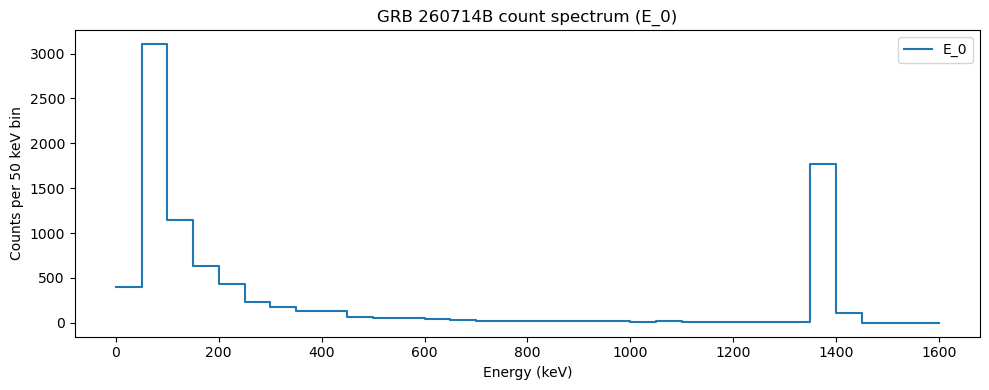

In [20]:
# TODO 14：创建计数能谱画布。
fig, ax = plt.subplots(figsize=(10, 4))

# TODO 15：补齐阶梯线末端，并画出各能量箱事件数。
spectrum_y = np.append(energy_counts, energy_counts[-1])
ax.step(energy_edges, spectrum_y, where="post", label="E_0")

# TODO 16：添加标题、带单位的坐标轴名称和图例。
ax.set_title("GRB 260714B count spectrum (E_0)")
ax.set_xlabel("Energy (keV)")
ax.set_ylabel("Counts per 50 keV bin")
ax.legend()

# TODO 17：保存并显示图片。
fig.tight_layout()
fig.savefig("count_spectrum.png", dpi=150, bbox_inches="tight")
plt.show()

## 参考资料

- [Python 官方教程](https://docs.python.org/zh-cn/3/tutorial/)
- [NumPy 快速入门](https://numpy.org/doc/stable/user/quickstart.html)
- [pandas 入门教程](https://pandas.pydata.org/docs/getting_started/intro_tutorials/)
- [DuckDB Python API](https://duckdb.org/docs/stable/clients/python/overview)
- [Matplotlib 教程](https://matplotlib.org/stable/tutorials/index.html)
